In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patato as pat
from tqdm.auto import tqdm

from mitox import setup_matplotlib

setup_matplotlib()

In [2]:
pa_phantom = pat.PAData.from_hdf5("../Data/PAISKINTONE/SKIN01/Scan_1.hdf5")

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../Data/PAISKINTONE/SKIN01/Scan_1.hdf5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
p0 = Path("../Data")

REC_TYPE = ("Model Based", "0")

In [ ]:
results = []
scan_names = set()
i = 0
for p in tqdm(list(p0.glob("**/*.hdf5"))):
    if "PROSPAX" in p.parent.stem:
        continue
    pa = pat.PAData.from_hdf5(p)  # type:ignore
    recs = pa.get_scan_reconstructions()
    assert isinstance(recs, dict)
    if REC_TYPE not in recs:
        continue
    scan_names.add(pa.get_scan_name())
    if (
        "phantom" not in pa.get_scan_name().lower()
        and "step" not in pa.get_scan_name().lower()
    ):
        continue
    if pa.scan_reader.file.attrs.get("DeviceSN", "2-22-01") != "2-22-01":  # type: ignore
        continue
    pa.external_roi_interface = pa_phantom  # type: ignore
    rec = pa.get_scan_reconstructions()[REC_TYPE]
    for r, roi in pa.get_rois().items():
        mask, _ = roi.to_mask_slice(rec)  # type: ignore
        spectrum = np.mean(rec.raw_data.T[mask.T].T, axis=(0, 2))  # type: ignore
        results.append({
            "Study": "MITOX",
            "RoiName": " ".join(r),
            "Spectrum": spectrum,
            "Wavelengths": pa.get_wavelengths(),
            "ID": p.parent.stem,
        })
    if i == 0:
        print(pa.get_scan_reconstructions()[REC_TYPE].attributes)
    i += 1

  0%|          | 0/1781 [00:00<?, ?it/s]

{'Bandpass': array([5.e+03, 7.e+06]), 'BandpassDetails': 'Scipy Butter Bandpass, 5kHz to 7MHz. Padtype even, padlen 100.', 'Damp': np.float64(300.0), 'RECONSTRUCTION_ALGORITHM': 'Model Based', 'RECONSTRUCTION_FIELD_OF_VIEW_X': np.float64(0.04), 'RECONSTRUCTION_FIELD_OF_VIEW_Y': np.float64(0.0), 'RECONSTRUCTION_FIELD_OF_VIEW_Z': np.float64(0.04), 'RECONSTRUCTION_NX': np.int64(400), 'RECONSTRUCTION_NY': np.int64(1), 'RECONSTRUCTION_NZ': np.int64(400), 'speedofsound': np.int64(1520), 'wavelengths': array([680., 690., 700., 710., 720., 730., 740., 750., 760., 770., 780.,
       790., 800., 810., 820., 830., 840., 850., 860., 870., 880., 890.,
       900., 910., 920., 930., 940., 950., 960., 970., 980.])}


,Study,RoiName,Spectrum,Wavelengths,ID
16,MITOX,phantom_ 2,"[-0.00444985022234611, -0.0034715094680790384,...","[680.0, 690.0, 700.0, 710.0, 720.0, 730.0, 740...",MITOX_19
106,MITOX,phantom_ 2,"[-0.0044307156755714, -0.004322572273117726, -...","[680.0, 690.0, 700.0, 710.0, 720.0, 730.0, 740...",SKIN26


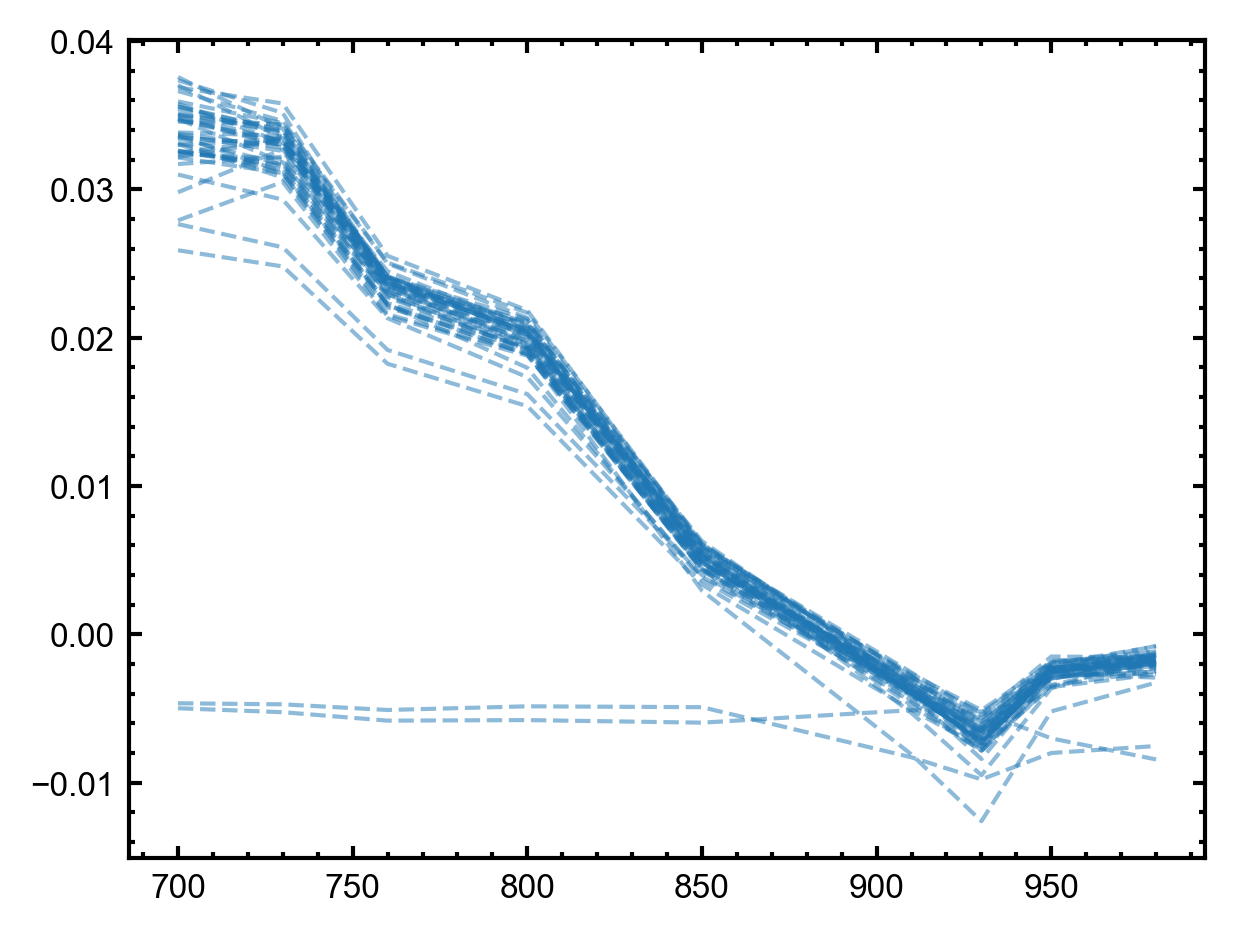

In [ ]:
df = pd.DataFrame(results)

wl_to_plot = np.array([700.0, 730.0, 760.0, 800.0, 850.0, 910.0, 930.0, 950.0, 980.0])

order = [
    "background_ 0",
    "background_ 1",
    "phantom_ 0",
    "phantom_ 1",
    "phantom_ 2",
    "phantom_ 3",
]
linestyle = {"MITOX": "--", "PAISKINTONE": "-.", "MITOX Original": "-"}
color_test = {"MITOX": "C0", "PAISKINTONE": "C1", "MITOX Original": "C2"}
for (s, r), g in df.groupby(["Study", "RoiName"]):
    if r != "phantom_ 2":
        continue
    display(g[g["Spectrum"].apply(lambda x: x[0]) < 0])
    g["Indices"] = g["Wavelengths"].apply(
        lambda x: np.where(x[:, None] == wl_to_plot[None, :])[0]  # type: ignore
    )
    spectra = np.stack(
        g[["Spectrum", "Indices"]].apply(lambda x: x["Spectrum"][x["Indices"]], axis=1)  # type: ignore
    )
    plt.plot(
        wl_to_plot,
        spectra.T,
        label=s + r,  # type: ignore
        color=color_test[s],  # f"C{order.index(r)}", # type: ignore
        linestyle=linestyle[s],  # type: ignore
        alpha=0.5,
    )
# plt.legend()
plt.show()